# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *(The goal of this assignment is to build a binary classification model that predicts whether a breast mass is malignant (0) or benign (1) using 30 numerical features derived from FNA cell nuclei images. In this domain, a false negative (predicting a tumor is benign when it is actually malignant) is far more dangerous than a false positive because failing to diagnose cancer can delay life-saving treatment. Therefore, I will evaluate success primarily based on high recall for the malignant class, while also monitoring overall accuracy and ROC-AUC.)*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [2]:
# TODO: load the dataset and copy its DataFrame into df

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [3]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows

print("Dataset Shape:", df.shape)
print("\nData Types Count:")
print(df.dtypes.value_counts())
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (569, 31)

Data Types Count:
float64    30
int64       1
Name: count, dtype: int64

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [4]:
# TODO: class counts and percentages
counts = df['target'].value_counts()
proportions = df['target'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({'Count': counts, 'Percentage (%)': proportions})
print(summary_df)

        Count  Percentage (%)
target                       
1         357       62.741652
0         212       37.258348


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [5]:
# TODO: describe().T, then the 10 largest skewness values
print("Summary Statistics:")
display(df.describe().T)

# 10 features with the highest skewness (excluding the target column)
skewed_features = df.drop(columns=['target']).skew().sort_values(ascending=False).head(10)
print("\n10 Most Skewed Features:")
print(skewed_features)

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 Most Skewed Features:
area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [6]:
# TODO: correlation with target, sorted
correlations = df.corr()['target'].drop('target').sort_values()

print("5 Most Negative Correlations with Target (Malignant predictors):")
print(correlations.head(5))

print("\n5 Most Positive Correlations with Target (Benign predictors):")
print(correlations.tail(5))

5 Most Negative Correlations with Target (Malignant predictors):
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations with Target (Benign predictors):
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *(The dataset has a mild class imbalance (roughly 63% benign vs. 37% malignant), which means standard accuracy alone can be misleading because a model could achieve decent accuracy just by favoring the majority class. Therefore, metrics like recall, F1-score, and ROC-AUC are better for evaluation.)*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

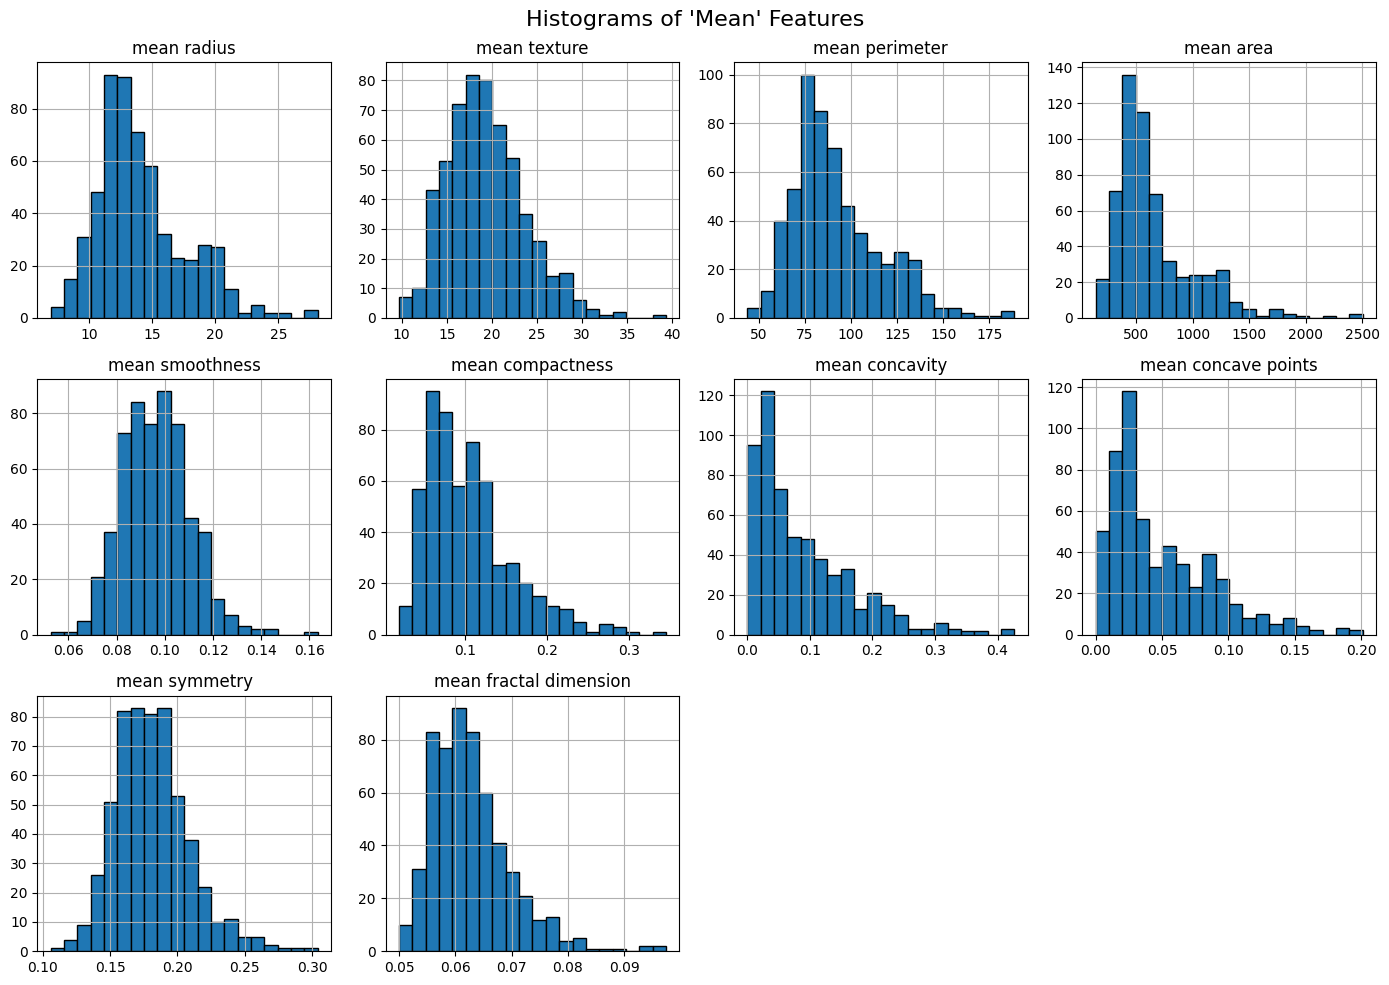

In [9]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)

mean_features = df.filter(like="mean")
mean_features.hist(bins=20, figsize=(14, 10), layout=(3, 4), edgecolor='black')
plt.suptitle("Histograms of 'Mean' Features", fontsize=16)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

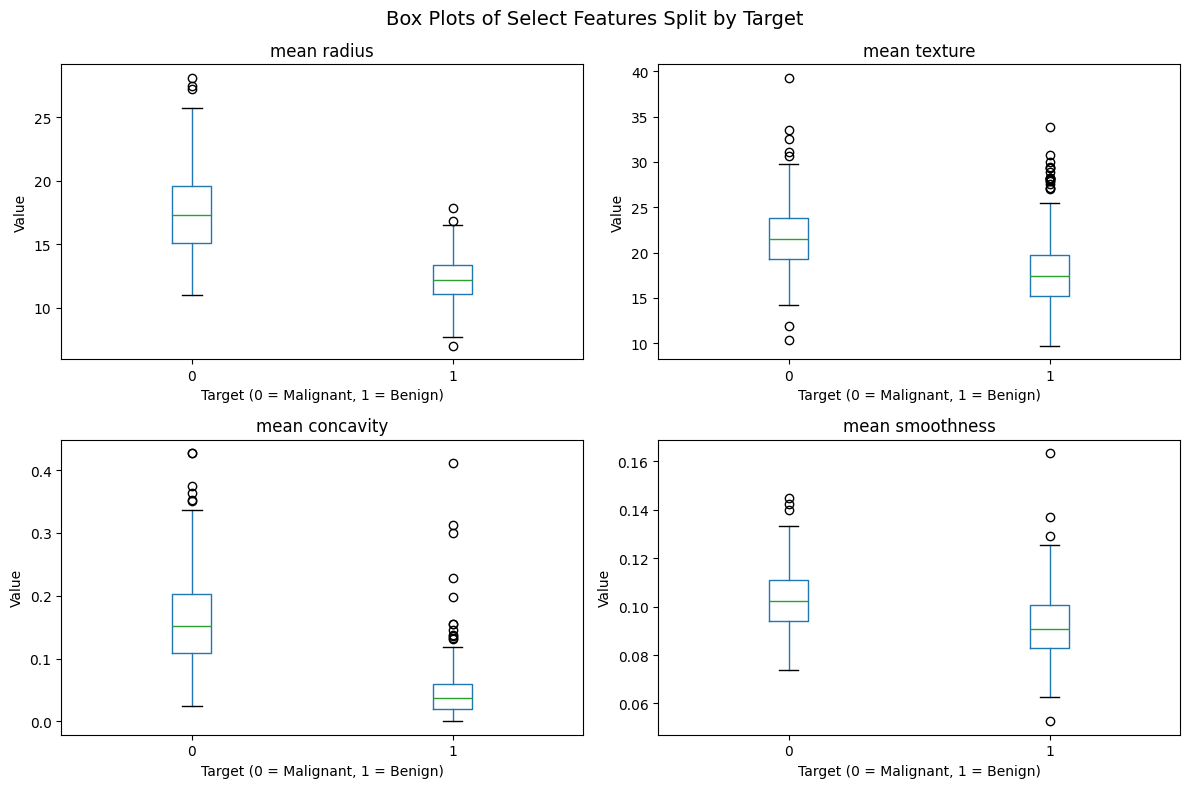

In [10]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    df.boxplot(column=col, by="target", ax=axes[i], grid=False)
    axes[i].set_title(col)
    axes[i].set_xlabel("Target (0 = Malignant, 1 = Benign)")
    axes[i].set_ylabel("Value")

plt.suptitle("Box Plots of Select Features Split by Target", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

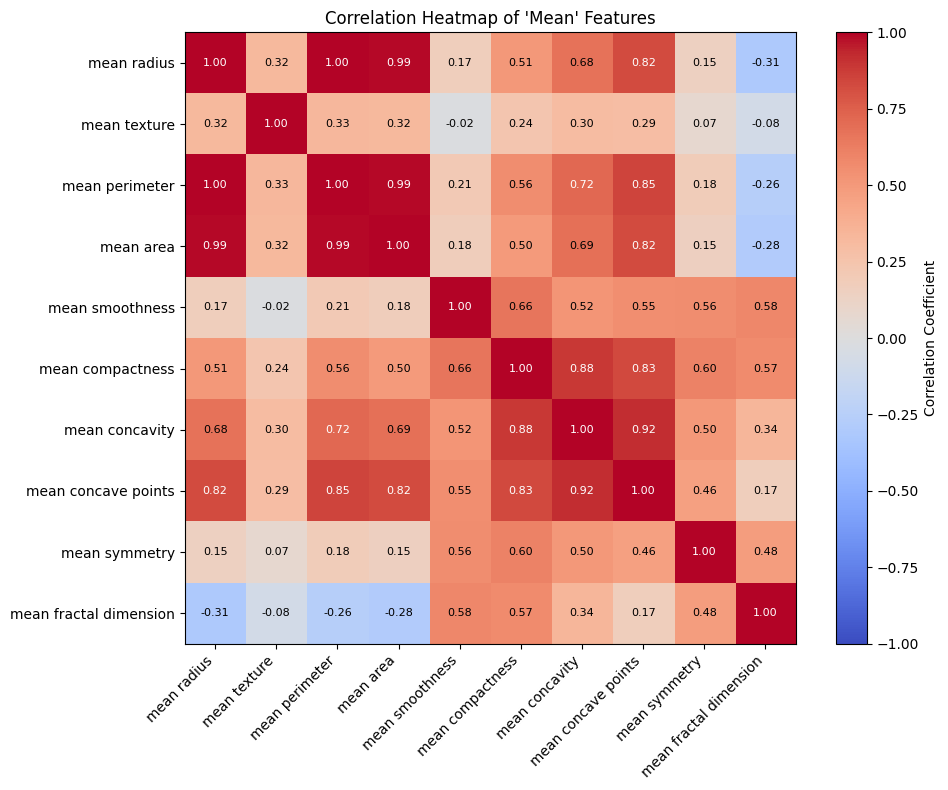

In [11]:
# TODO: correlation matrix of the "mean" features drawn with imshow

mean_df = df.filter(like="mean")
corr_matrix = mean_df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation Coefficient')

# Add tick labels
plt.xticks(ticks=range(len(mean_df.columns)), labels=mean_df.columns, rotation=45, ha='right')
plt.yticks(ticks=range(len(mean_df.columns)), labels=mean_df.columns)

# Add correlation values inside heatmap cells
for i in range(corr_matrix.shape[0]):
    for j in range(corr_matrix.shape[1]):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center',
                 color='black' if abs(corr_matrix.iloc[i, j]) < 0.7 else 'white', fontsize=8)

plt.title("Correlation Heatmap of 'Mean' Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

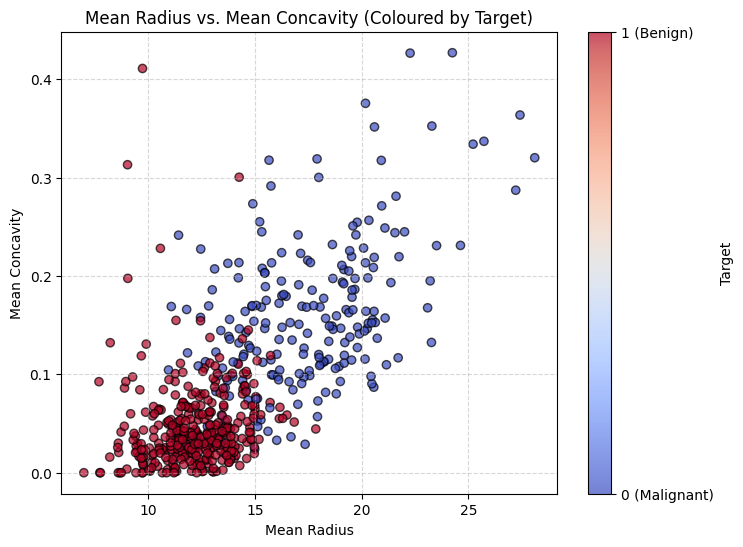

In [12]:
# TODO: coloured scatter plot with axis labels and a colourbar

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['mean radius'], df['mean concavity'], c=df['target'], cmap='coolwarm', alpha=0.7, edgecolors='k')

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity (Coloured by Target)")

cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_label("Target")
cbar.ax.set_yticklabels(['0 (Malignant)', '1 (Benign)'])

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** *(Size-related metrics like mean radius, mean perimeter, and mean area appear highly redundant because they share near-perfect correlations. The same applies to mean concavity and mean concave points, which track almost identical shape traits.)*

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [7]:
# TODO: total missing values and duplicated rows

print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]


Total missing values: 0
Total duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [8]:
# TODO: IQR outlier count per feature

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR)))
outlier_counts = outliers.sum().sort_values(ascending=False)

print("Top 10 features with the most outliers:")
print(outlier_counts.head(10))

Top 10 features with the most outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *(No, I would not delete the outlying rows. In medical datasets, extreme feature values often represent genuine clinical variation—such as unusually large or irregularly shaped cell nuclei—which are critical indicators of malignant tumors rather than mere measurement errors. Removing these instances could erase important diagnostic signals and cause the model to perform poorly on severe or rare cases. Instead of dropping data, I can use robust scaling, power transformations, or tree-based algorithms that handle outliers well.)*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [13]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
print("Features with correlation > 0.95 with an earlier feature:", high_corr_features)

Features with correlation > 0.95 with an earlier feature: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [14]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
kbest = SelectKBest(score_func=f_classif, k=10)
kbest.fit(X, y)

kbest_scores = pd.Series(kbest.scores_, index=X.columns).sort_values(ascending=False)
kbest_top10 = kbest_scores.head(10).index.tolist()

print("Top 10 features by SelectKBest (ANOVA F-score):")
print(kbest_scores.head(10))

Top 10 features by SelectKBest (ANOVA F-score):
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [15]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe_model = LogisticRegression(max_iter=1000, random_state=7)
rfe = RFE(estimator=rfe_model, n_features_to_select=10)
rfe.fit(X_scaled, y)

rfe_features = list(X.columns[rfe.support_])
print("10 features selected by RFE:")
print(rfe_features)

10 features selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

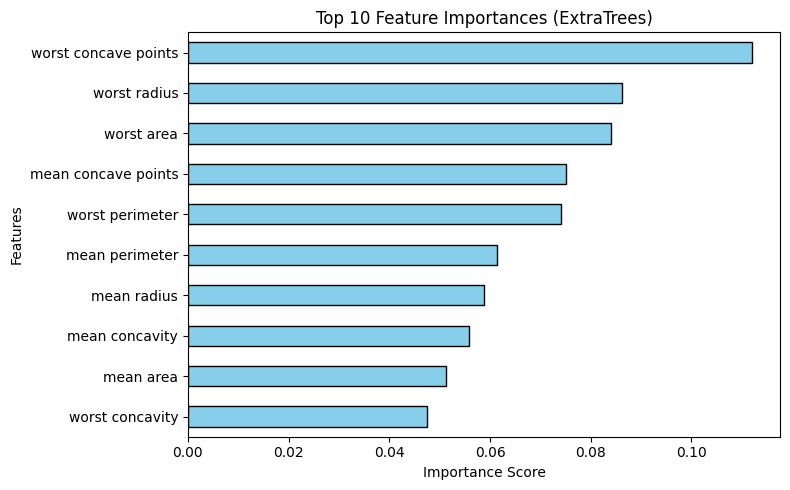

In [16]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=True)
et_top10 = imp.tail(10).index.tolist()

plt.figure(figsize=(8, 5))
imp.tail(10).plot(kind='barh', color='skyblue', edgecolor='black')
plt.title("Top 10 Feature Importances (ExtraTrees)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [17]:
# TODO: vote across the three methods
from collections import Counter

all_selected_features = kbest_top10 + rfe_features + et_top10

feature_counts = Counter(all_selected_features)

selected = [feature for feature, count in feature_counts.items() if count >= 2]

print(f"Selected {len(selected)} features supported by at least 2 methods:")
print(selected)

Selected 10 features supported by at least 2 methods:
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [23]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=7
)

print("Train shape, Test shape:", X_train.shape, X_test.shape)

Train shape, Test shape: (455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [22]:
# TODO: fit both scalers on X_train and print the verifying statistics

std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(X_train)

minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)

first_4_cols = X.columns[:4]

print("--- Standardized Training Data (First 4 Features) ---")
print("Means:", np.round(X_train_std[:, :4].mean(axis=0), 4))
print("Stds: ", np.round(X_train_std[:, :4].std(axis=0), 4))

print("\n--- MinMax Scaled Training Data (First 4 Features) ---")
print("Mins: ", np.round(X_train_minmax[:, :4].min(axis=0), 4))
print("Maxs: ", np.round(X_train_minmax[:, :4].max(axis=0), 4))

--- Standardized Training Data (First 4 Features) ---
Means: [ 0. -0. -0. -0.]
Stds:  [1. 1. 1. 1.]

--- MinMax Scaled Training Data (First 4 Features) ---
Mins:  [0. 0. 0. 0.]
Maxs:  [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [21]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance

pca = PCA()
pca.fit(X_train_std)

cum_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cum_variance >= 0.95) + 1

print(f"Number of components retaining 95% variance: {n_components_95}")
print(f"Cumulative explained variance with {n_components_95} components: {cum_variance[n_components_95 - 1]:.4f}")

Number of components retaining 95% variance: 10
Cumulative explained variance with 10 components: 0.9560


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [24]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR": LogisticRegression(random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [25]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled

raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: res.mean() for name, res in raw_results.items()},
    "scaled": {name: res.mean() for name, res in scaled_results.items()}
})

print(summary)

           raw    scaled
LR    0.938357  0.982319
LDA   0.947246  0.947246
KNN   0.922947  0.964928
CART  0.927633  0.927633
NB    0.934058  0.932029
SVM   0.898696  0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *(Distance-based algorithms like KNN and SVM, as well as gradient-based linear models like Logistic Regression, benefit significantly from feature scaling. KNN relies on Euclidean distance, so features with larger raw numeric magnitudes would dominate the distance calculation without scaling. Similarly, SVM relies on maximizing margin boundaries and performs poorly when features aren't on comparable scales. Linear Discriminant Analysis also benefits because scaling helps stabilize the estimation of feature covariances. Decision trees (CART) show little to no change because tree splits are invariant to monotonic feature transformations.)*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [26]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
scaled_selected_results = spot_check(models, X_train[selected], scale=True)

fs_summary = pd.DataFrame({
    "Scaled (All Features)": summary["scaled"],
    "Scaled (Selected Features)": {name: res.mean() for name, res in scaled_selected_results.items()}
})

print(fs_summary)

      Scaled (All Features)  Scaled (Selected Features)
LR                 0.982319                    0.960435
LDA                0.947246                    0.942995
KNN                0.964928                    0.942802
CART               0.927633                    0.925266
NB                 0.932029                    0.951691
SVM                0.975797                    0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

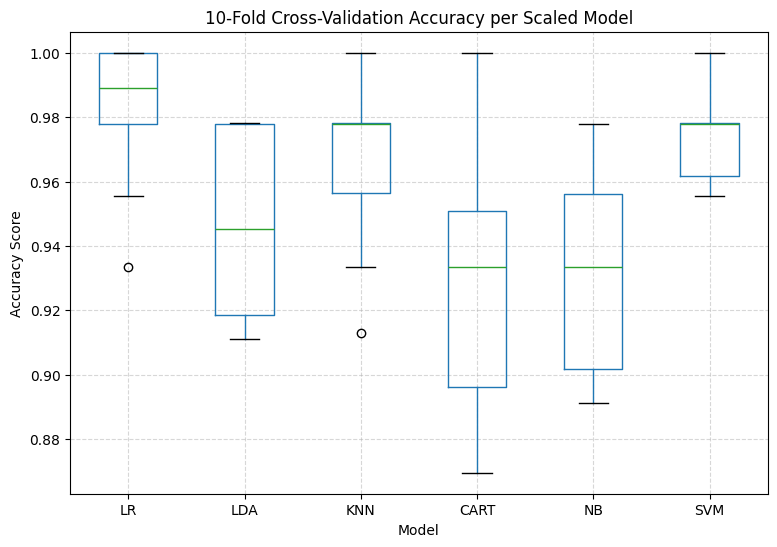

In [27]:
# TODO: box plot of the 10 fold scores per model
scaled_df = pd.DataFrame(scaled_results)

plt.figure(figsize=(9, 6))
scaled_df.boxplot()
plt.title("10-Fold Cross-Validation Accuracy per Scaled Model")
plt.xlabel("Model")
plt.ylabel("Accuracy Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [28]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
malignant_recall = make_scorer(recall_score, pos_label=0)

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "malignant_recall": malignant_recall
}

best_model_name = summary["scaled"].idxmax()
best_model = models[best_model_name]

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

cv_results = cross_validate(pipeline, X_train, y_train, cv=kfold, scoring=scoring)

print(f"Detailed CV Performance for Best Model ({best_model_name}):")
print(f"Mean Accuracy:         {cv_results['test_accuracy'].mean():.4f} +/- {cv_results['test_accuracy'].std():.4f}")
print(f"Mean ROC-AUC:          {cv_results['test_roc_auc'].mean():.4f} +/- {cv_results['test_roc_auc'].std():.4f}")
print(f"Mean Malignant Recall: {cv_results['test_malignant_recall'].mean():.4f} +/- {cv_results['test_malignant_recall'].std():.4f}")

Detailed CV Performance for Best Model (LR):
Mean Accuracy:         0.9823 +/- 0.0218
Mean ROC-AUC:          0.9922 +/- 0.0107
Mean Malignant Recall: 0.9647 +/- 0.0471


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [29]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
import joblib
from sklearn.model_selection import GridSearchCV

pipe_svm = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(random_state=seed))
])

param_grid_svm = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=kfold, scoring="accuracy", n_jobs=-1)
grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_
print("Best SVM Params:", grid_svm.best_params_)
print("Best SVM CV Score:", grid_svm.best_score_)

Best SVM Params: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV Score: 0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [30]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
pipe_knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=kfold, scoring="accuracy", n_jobs=-1)
grid_knn.fit(X_train, y_train)

best_knn = grid_knn.best_estimator_
print("Best KNN Params:", grid_knn.best_params_)
print("Best KNN CV Score:", grid_knn.best_score_)

Best KNN Params: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV Score: 0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [31]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
ensembles = {
    "RF": RandomForestClassifier(random_state=seed),
    "ET": ExtraTreesClassifier(random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "Ada": AdaBoostClassifier(random_state=seed)
}

ensemble_results = spot_check(ensembles, X_train, scale=False)

rf_model = RandomForestClassifier(random_state=seed)
voting_clf = VotingClassifier(
    estimators=[
        ("svm", best_svm),
        ("knn", best_knn),
        ("rf", rf_model)
    ],
    voting="hard"
)

voting_scores = cross_val_score(voting_clf, X_train, y_train, cv=kfold, scoring="accuracy")
print("Voting Classifier CV Score:", voting_scores.mean())

Voting Classifier CV Score: 0.9780676328502416


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [32]:
# TODO: leaderboard Series
leaderboard_dict = {
    "Tuned SVM": grid_svm.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "Random Forest": ensemble_results["RF"].mean(),
    "Extra Trees": ensemble_results["ET"].mean(),
    "Gradient Boosting": ensemble_results["GBM"].mean(),
    "AdaBoost": ensemble_results["Ada"].mean(),
    "Voting Classifier": voting_scores.mean()
}

leaderboard = pd.Series(leaderboard_dict).sort_values(ascending=False)
print("--- Model Leaderboard (CV Accuracy) ---")
print(leaderboard)

--- Model Leaderboard (CV Accuracy) ---
Tuned SVM            0.980193
Voting Classifier    0.978068
Extra Trees          0.973575
Tuned KNN            0.969275
Random Forest        0.969130
Gradient Boosting    0.966957
AdaBoost             0.962560
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM
Test Set Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



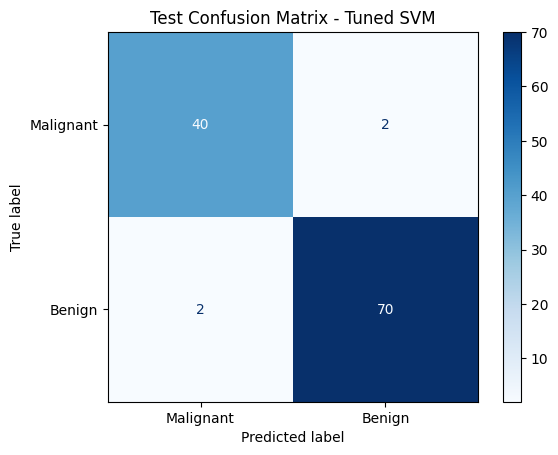

In [33]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
winner_name = leaderboard.index[0]
print(f"Winning Model: {winner_name}")

model_mapping = {
    "Tuned SVM": best_svm,
    "Tuned KNN": best_knn,
    "Random Forest": Pipeline([("scale", StandardScaler()), ("model", ensembles["RF"])]),
    "Extra Trees": Pipeline([("scale", StandardScaler()), ("model", ensembles["ET"])]),
    "Gradient Boosting": Pipeline([("scale", StandardScaler()), ("model", ensembles["GBM"])]),
    "AdaBoost": Pipeline([("scale", StandardScaler()), ("model", ensembles["Ada"])]),
    "Voting Classifier": voting_clf
}

final_model = model_mapping[winner_name]
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
print(f"Test Set Accuracy: {test_acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Malignant", "Benign"], cmap="Blues"
)
plt.title(f"Test Confusion Matrix - {winner_name}")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [34]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
joblib.dump(final_model, "final_breast_cancer_model.pkl")

loaded_model = joblib.load("final_breast_cancer_model.pkl")
loaded_preds = loaded_model.predict(X_test)

print("First 5 Actual Targets:    ", y_test.iloc[:5].values)
print("First 5 Loaded Predictions:", loaded_preds[:5])
print("Predictions Match Exactly:", np.array_equal(y_pred, loaded_preds))

First 5 Actual Targets:     [0 0 1 0 1]
First 5 Loaded Predictions: [0 0 1 0 1]
Predictions Match Exactly: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`. *(Performing feature selection on the entire dataset allows information from the test folds and holdout data to leak into the training process, giving the selection algorithm unfair knowledge about target correlations across the whole population. This artificially inflates cross-validation scores because the model evaluates features that were chosen using data it shouldn't have seen yet. To fix this, feature selection must be placed inside a Pipeline object alongside the estimator. When passed to cross-validation, the pipeline ensures that feature selection is fit strictly on the training split of each individual fold.)*
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient? *(I would report recall for the malignant class alongside ROC-AUC to a clinician. Accuracy alone is insufficient because, in a clinical diagnostic setting, false negatives carry a disastrously high cost—misclassifying a malignant tumor as benign can delay urgent medical intervention and prove fatal. High overall accuracy could easily mask a model that predicts benign too aggressively, so tracking sensitivity guarantees that almost all actual malignant tumors are correctly flagged for follow-up.)*
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? *(Think variance across folds, interpretability, training cost.) *(A 0.3% difference in cross-validation accuracy is negligible and likely statistically insignificant across 10 folds. I would decide between them by prioritizing lower variance across cross-validation folds, higher model interpretability, and operational efficiency. If a simpler, faster, or highly interpretable model (like Logistic Regression or linear SVM) performs within 0.3% of a complex ensemble, I would choose the simpler model because it is easier to audit, easier to deploy, and less prone to overfitting on unseen data.)*
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset? *(If the dataset were much smaller, model performance variance across folds would increase significantly, making cross-validation scores less reliable and increasing the risk of overfitting—forcing us to prefer simpler linear models with strong regularization. If the dataset were heavily imbalanced, accuracy would become a useless evaluation metric, and standard classifiers would default to predicting the majority class.)*
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change. *(If repeating this notebook with a new dataset loaded from an ARFF file, the initial loading step would change to use scipy.io.arff.loadarff or liac-arff instead of sklearn.datasets. Beyond data ingestion, the core workflow remains identical, though specific preprocessing steps would adjust based on the data: handling categorical attributes via one-hot encoding, imputing missing values if present, adjusting scaling methods, and altering cross-validation strategies if dealing with multi-class targets instead of binary classification.)*

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.